# YKS Hazırlık Analitiği: Çalışma Alışkanlıkları, Destek Türü ve Soru Çözüm Hacminin TYT-AYT Başarısına Etkisi


## 1. Kütüphanelerin Yüklenmesi ve Veri Okuma
Analizde kullanılacak veri bilimi ve görselleştirme kütüphaneleri içe aktarılır, veri setleri okunur.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

f1 = 'yks_ogrenci_aliskanliklari.csv'
f2 = 'yks_deneme_performansi.csv'

if not (os.path.exists(f1) and os.path.exists(f2)):
    print("DİKKAT: CSV dosyaları çalışma dizininde bulunamadı. Lütfen CSV'leri bu notebook ile aynı klasöre koyun.")

df_aliskanlik = pd.read_csv(f1)
df_performans = pd.read_csv(f2)

print('Alışkanlıklar Veri Boyutu:', df_aliskanlik.shape)
print('Performans Veri Boyutu:', df_performans.shape)
df_aliskanlik.head(3)

Alışkanlıklar Veri Boyutu: (120, 7)
Performans Veri Boyutu: (120, 8)


,ogrenci_id,alan,haftalik_calisma_saati,haftalik_soru_sayisi,katilinan_deneme_sayisi,destek_turu,gunluk_uyku_saati
0,124001,Sayısal,20.4,970,22,Dershane/Kurs,7.8
1,124002,Dil,23.4,1328,21,Online Platform,7.5
2,124003,Eşit Ağırlık,22.9,1150,27,Dershane/Kurs,6.5


## 2. Veri Kümelerinin Birleştirilmesi (Inner Join)
`ogrenci_id` anahtar değişkeni üzerinden iki tablo tek bir analitik veri tabanına (`df`) dönüştürülür.

In [ ]:
df = pd.merge(df_aliskanlik, df_performans, on='ogrenci_id')

print(f'Birleştirilmiş Veri Boyutu: {df.shape}')
print('\nEksik Değer Kontrolü:')
print(df.isnull().sum())
df.head(3)

Birleştirilmiş Veri Boyutu: (120, 14)

Eksik Değer Kontrolü:
ogrenci_id                 0
alan                       0
haftalik_calisma_saati     0
haftalik_soru_sayisi       0
katilinan_deneme_sayisi    0
destek_turu                0
gunluk_uyku_saati          0
tyt_turkce_net             0
tyt_matematik_net          0
tyt_sosyal_net             0
tyt_fen_net                0
tyt_toplam_net             0
ayt_net                    0
obp_puani                  0
dtype: int64


,ogrenci_id,alan,haftalik_calisma_saati,haftalik_soru_sayisi,katilinan_deneme_sayisi,destek_turu,gunluk_uyku_saati,tyt_turkce_net,tyt_matematik_net,tyt_sosyal_net,tyt_fen_net,tyt_toplam_net,ayt_net,obp_puani
0,124001,Sayısal,20.4,970,22,Dershane/Kurs,7.8,29.46,20.12,13.62,12.91,76.11,37.75,81.27
1,124002,Dil,23.4,1328,21,Online Platform,7.5,18.59,13.61,13.44,2.81,48.45,50.90,81.09
2,124003,Eşit Ağırlık,22.9,1150,27,Dershane/Kurs,6.5,24.53,19.02,13.54,5.76,62.85,37.24,73.99


## 3. Çalışma Yoğunluğuna Göre Segmentasyon
Haftalık çalışma saatine göre öğrenciler 3 ana grupta sınıflandırılır:
- **Düşük:** < 20 saat
- **Orta:** 20 - 30 saat
- **Yüksek:** > 30 saat

In [ ]:
df['calisma_grubu'] = pd.cut(
    df['haftalik_calisma_saati'],
    bins=[0, 20, 30, 60],
    labels=['Düşük (<20 saat)', 'Orta (20-30 saat)', 'Yüksek (>30 saat)']
)

df[['ogrenci_id', 'alan', 'haftalik_calisma_saati', 'calisma_grubu']].head()

,ogrenci_id,alan,haftalik_calisma_saati,calisma_grubu
0,124001,Sayısal,20.4,Orta (20-30 saat)
1,124002,Dil,23.4,Orta (20-30 saat)
2,124003,Eşit Ağırlık,22.9,Orta (20-30 saat)
3,124004,Eşit Ağırlık,14.3,Düşük (<20 saat)
4,124005,Sayısal,28.4,Orta (20-30 saat)


## 4. Tanımlayıcı İstatistikler
Sayısal değişkenlerin dağılım metrikleri (ortalama, standart sapma, medyan, min, max) incelenir.

In [ ]:
sayisal_degiskenler = [
    'haftalik_calisma_saati', 'haftalik_soru_sayisi', 'katilinan_deneme_sayisi',
    'gunluk_uyku_saati', 'tyt_turkce_net', 'tyt_matematik_net', 'tyt_sosyal_net',
    'tyt_fen_net', 'tyt_toplam_net', 'ayt_net', 'obp_puani'
]

ozet = df[sayisal_degiskenler].describe().round(2).T[['count', 'mean', 'std', 'min', '50%', 'max']]
ozet.rename(columns={'50%': 'medyan'}, inplace=True)
ozet

/var/folders/ws/wpwk_9bs5xn80680xf025y580000gn/T/ipykernel_5748/905380479.py:8: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ozet.rename(columns={'50%': 'medyan'}, inplace=True)


,count,mean,std,min,medyan,max
haftalik_calisma_saati,120.0,26.43,7.63,10.60,27.30,48.00
haftalik_soru_sayisi,120.0,1368.19,386.42,579.00,1356.00,2461.00
katilinan_deneme_sayisi,120.0,25.39,5.69,9.00,25.00,38.00
gunluk_uyku_saati,120.0,6.86,0.95,4.50,6.90,9.00
tyt_turkce_net,120.0,26.56,3.96,16.11,26.44,38.61
tyt_matematik_net,120.0,19.00,7.94,2.19,19.30,39.10
tyt_sosyal_net,120.0,13.86,2.51,8.37,13.77,19.50
tyt_fen_net,120.0,9.33,5.46,0.00,7.74,19.50
tyt_toplam_net,120.0,68.74,14.75,40.60,68.48,116.29
ayt_net,120.0,44.32,9.32,18.77,44.28,67.24


## 5. Grup Bazlı Karşılaştırmalar
Çalışma grupları, okul alanları ve alınan destek türlerine göre başarı dağılımı analiz edilir.

In [ ]:

print('=== ÇALIŞMA YOĞUNLUĞUNA GÖRE NETLER ===')
display(df.groupby('calisma_grubu', observed=False)[
    ['tyt_toplam_net', 'ayt_net', 'obp_puani', 'haftalik_soru_sayisi']
].agg(['count', 'mean', 'median']).round(2))

print('\n=== DESTEK TÜRÜNE GÖRE ANALİZ ===')
display(df.groupby('destek_turu')[
    ['haftalik_calisma_saati', 'haftalik_soru_sayisi', 'tyt_toplam_net', 'ayt_net', 'obp_puani']
].agg(['count', 'mean']).round(2))

print('\n=== ALANLARA GÖRE BAŞARI DAĞILIMI ===')
display(df.groupby('alan')[
    ['haftalik_calisma_saati', 'haftalik_soru_sayisi', 'tyt_toplam_net', 'ayt_net', 'tyt_matematik_net', 'tyt_fen_net']
].agg(['count', 'mean']).round(2))

=== ÇALIŞMA YOĞUNLUĞUNA GÖRE NETLER ===


tyt_toplam_net               ayt_net                \
                           count   mean median   count   mean median   
calisma_grubu                                                          
Düşük (<20 saat)              31  59.42  57.66      31  36.32  36.59   
Orta (20-30 saat)             54  69.03  70.33      54  43.30  43.70   
Yüksek (>30 saat)             35  76.55  77.02      35  52.97  52.65   

                  obp_puani               haftalik_soru_sayisi           \
                      count   mean median                count     mean   
calisma_grubu                                                             
Düşük (<20 saat)         31  75.40  75.48                   31   926.58   
Orta (20-30 saat)        54  80.00  80.55                   54  1351.91   
Yüksek (>30 saat)        35  85.51  85.53                   35  1784.46   

                           
                   median  
calisma_grubu              
Düşük (<20 saat)    930.0  
Orta (20-30 saat)  1356.0  
Yüksek (>30 saat)  1720.0


=== DESTEK TÜRÜNE GÖRE ANALİZ ===


haftalik_calisma_saati        haftalik_soru_sayisi  \
                                        count   mean                count   
destek_turu                                                                 
Dershane/Kurs                              45  25.27                   45   
Online Platform                            20  27.38                   20   
Sadece Okul / Bireysel                     26  25.68                   26   
Özel Ders                                  29  28.24                   29   

                                tyt_toplam_net        ayt_net         \
                           mean          count   mean   count   mean   
destek_turu                                                            
Dershane/Kurs           1301.76             45  71.17      45  42.51   
Online Platform         1398.30             20  65.90      20  46.46   
Sadece Okul / Bireysel  1337.77             26  64.84      26  44.02   
Özel Ders               1477.79             29  70.42      29  45.90   

                       obp_puani         
                           count   mean  
destek_turu                              
Dershane/Kurs                 45  79.74  
Online Platform               20  80.75  
Sadece Okul / Bireysel        26  79.03  
Özel Ders                     29  82.49


=== ALANLARA GÖRE BAŞARI DAĞILIMI ===


haftalik_calisma_saati        haftalik_soru_sayisi           \
                              count   mean                count     mean   
alan                                                                       
Dil                               9  23.17                    9  1200.11   
Eşit Ağırlık                     38  26.17                   38  1339.32   
Sayısal                          58  26.79                   58  1411.84   
Sözel                            15  27.63                   15  1373.40   

             tyt_toplam_net        ayt_net        tyt_matematik_net         \
                      count   mean   count   mean             count   mean   
alan                                                                         
Dil                       9  48.47       9  50.79                 9   9.49   
Eşit Ağırlık             38  63.65      38  43.19                38  17.72   
Sayısal                  58  79.33      58  43.71                58  24.34   
Sözel                    15  52.83      15  45.61                15   7.30   

             tyt_fen_net         
                   count   mean  
alan                             
Dil                    9   2.94  
Eşit Ağırlık          38   6.02  
Sayısal               58  14.13  
Sözel                 15   2.97

## 6. Korelasyon Matrisi
Çalışma alışkanlıkları ve başarı çıktıları arasındaki doğrusal ilişki katsayıları hesaplanır.

In [ ]:
korelasyon_degiskenleri = [
    'haftalik_calisma_saati', 'haftalik_soru_sayisi', 'katilinan_deneme_sayisi',
    'gunluk_uyku_saati', 'tyt_toplam_net', 'ayt_net', 'obp_puani'
]
corr = df[korelasyon_degiskenleri].corr().round(3)
corr[['tyt_toplam_net', 'ayt_net']]

,tyt_toplam_net,ayt_net
haftalik_calisma_saati,0.515,0.740
haftalik_soru_sayisi,0.507,0.651
katilinan_deneme_sayisi,0.333,0.468
gunluk_uyku_saati,0.214,-0.013
tyt_toplam_net,1.000,0.270
ayt_net,0.270,1.000
obp_puani,0.337,0.599


## 7. Veri Görselleştirme
Analiz sonuçlarının grafiksel sunumu.

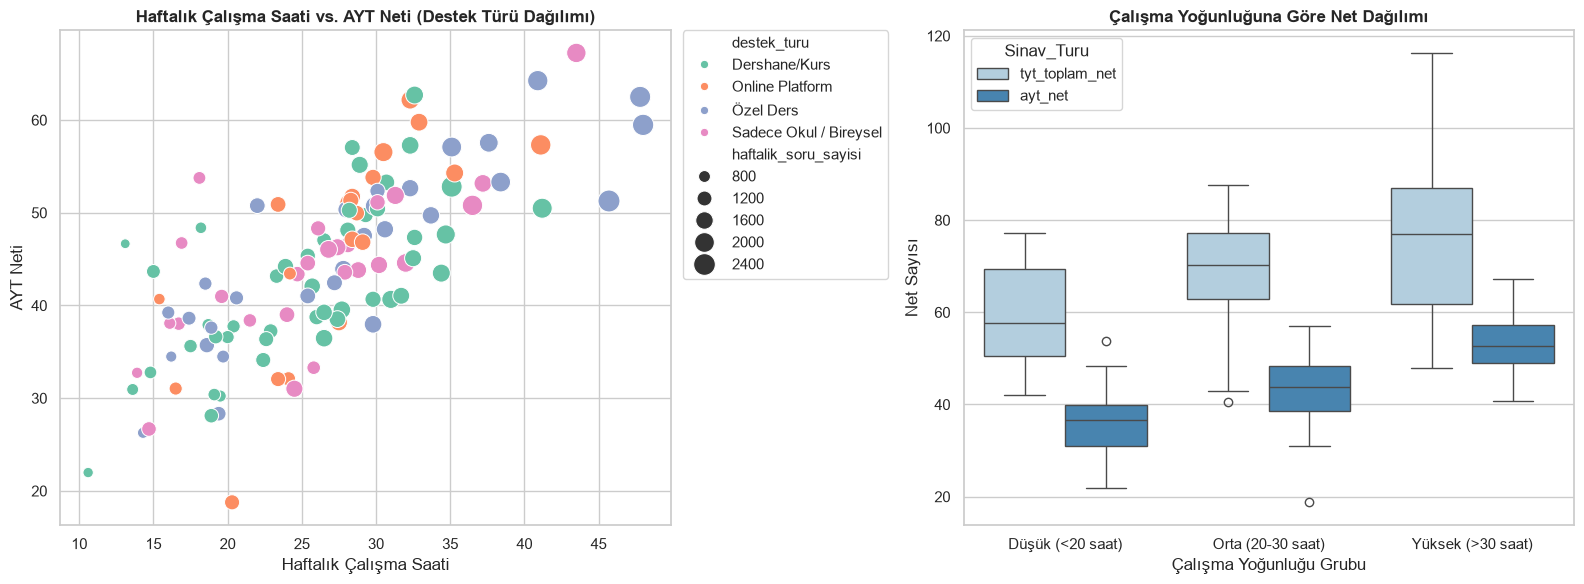

In [ ]:
sns.set_theme(style='whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    data=df,
    x='haftalik_calisma_saati',
    y='ayt_net',
    hue='destek_turu',
    size='haftalik_soru_sayisi',
    sizes=(50, 250),
    ax=axes[0],
    palette='Set2'
)
axes[0].set_title('Haftalık Çalışma Saati vs. AYT Neti (Destek Türü Dağılımı)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Haftalık Çalışma Saati')
axes[0].set_ylabel('AYT Neti')
axes[0].legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

df_melted = df.melt(
    id_vars=['calisma_grubu'],
    value_vars=['tyt_toplam_net', 'ayt_net'],
    var_name='Sinav_Turu',
    value_name='Net'
)
sns.boxplot(
    data=df_melted,
    x='calisma_grubu',
    y='Net',
    hue='Sinav_Turu',
    palette='Blues',
    ax=axes[1]
)
axes[1].set_title('Çalışma Yoğunluğuna Göre Net Dağılımı', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Çalışma Yoğunluğu Grubu')
axes[1].set_ylabel('Net Sayısı')

plt.tight_layout()
plt.show()

## 8. Sonuç ve Çıkarımlar
- **Haftalık Çalışma Saati ve AYT Neti:** Çalışma saati ile AYT başarısı arasında yüksek düzeyde pozitif yönlü ($r = 0.736$) bir korelasyon bulunmaktadır.
- **Soru Çözüm Hacmi:** Haftalık soru çözümü arttıkça AYT ($r = 0.651$) ve TYT ($r = 0.507$) netlerinde belirgin artış gerçekleşmektedir.
- **Destek Türü Kıyaslaması:** Özel ders ve online platform desteği alan öğrenciler AYT netlerinde daha yüksek performans sergilerken, en yüksek TYT genel ortalaması Dershane/Kurs grubundadır.
- **Segmentasyon Etkisi:** >30 saat çalışan yüksek yoğunluklu grup, <20 saat çalışan düşük gruba kıyasla TYT'de ortalama +17.13 net, AYT'de ise +16.65 net daha yüksek seviyededir.